# 3. The final model and the bedside tool

**Transplant or Wait** · Aya Bekhtiar, Apolline Hadjal

Notebook 2 selected **IPSS-M, recalibrated to a 2-year risk**. This notebook shows:

1. The two numbers estimated on this file, and the resulting formula
2. How risk rises with the IPSS-M score, and where the 30 % threshold falls
3. The 22 features and their weights
4. One prediction worked out by hand
5. The tool on every patient: bands, uncertainty, centre-to-centre range
6. A patient card, and how to score new patients (the held-out test set)

The frozen model is `models/final_model.json`, written by `scripts/03_train_final.py`; this notebook re-derives its key numbers and checks they match.

In [1]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from mds_tool import HORIZON_YEARS, cohort, metrics, plotting, scores
plotting.setup()
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
H = HORIZON_YEARS  # 2-year horizon

import json
from IPython.display import Image, display
from sksurv.linear_model import CoxPHSurvivalAnalysis
from mds_tool import features, tool
from mds_tool.model import _breslow_s0, surv_y

THRESHOLD = 0.30
frozen = json.load(open("models/final_model.json"))
df = cohort.load_all()
steps, masks = cohort.flow(df)
train = df[masks["in_scope"]]
print(f"intended-use cohort: {len(train)} patients, {int(train.OS_STATUS.sum())} deaths, {train.CENTER.nunique()} centres")

intended-use cohort: 2662 patients, 1299 deaths, 23 centres


## 1. Two numbers estimated on this file

The IPSS-M score keeps its published weights. We fit a one-variable Cox model of survival on the score to get (a) the **slope** linking one IPSS-M point to the hazard and (b) the **2-year baseline survival**.

In [2]:
score = train.IPSSM_score.values
slope = float(CoxPHSurvivalAnalysis().fit(score[:, None], surv_y(train)).coef_[0])
s0_at_zero = _breslow_s0(train.OS_YEARS.values, train.OS_STATUS.values, slope * score, H)   # baseline at score 0
print(f"slope per IPSS-M point:       {slope:.3f}   (frozen file: {frozen['recalibration_slope']:.3f})")
print(f"2-year survival at score 0:   {s0_at_zero:.3f}")
print(f"published scale for comparison: ln 2 = {np.log(2):.3f} per point -> every effect is shrunk to the power {slope / np.log(2):.2f}")

slope per IPSS-M point:       0.574   (frozen file: 0.574)
2-year survival at score 0:   0.684
published scale for comparison: ln 2 = 0.693 per point -> every effect is shrunk to the power 0.83


So the whole model is:

$$\text{2-year risk of death} \approx 1 - 0.684^{\,e^{0.57\,\times\,\text{IPSS-M score}}}$$

(The frozen file uses the unrounded score; the difference is in the third decimal.)

## 2. Risk against the IPSS-M score

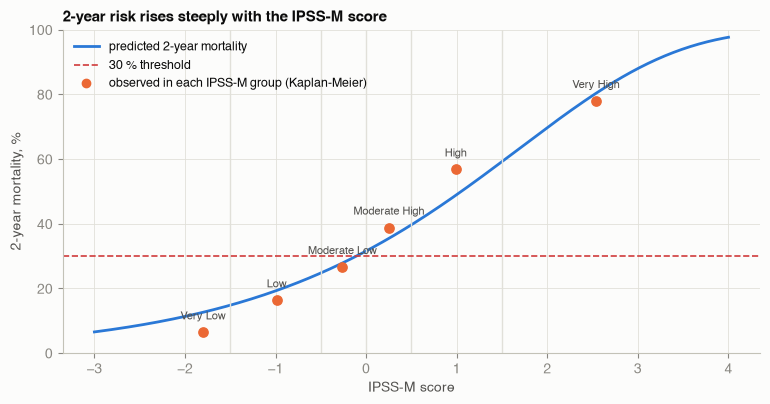

risk at the Moderate-Low / Moderate-High boundary (score 0): 31.6%


In [3]:
def risk_of(s):
    return 1 - s0_at_zero ** np.exp(slope * s)

xs = np.linspace(-3, 4, 300)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(xs, 100 * risk_of(xs), color=plotting.SERIES[0], label="predicted 2-year mortality")
cuts = [-1.5, -0.5, 0, 0.5, 1.5]
for c in cuts:
    ax.axvline(c, color=plotting.GRID, lw=1)
ax.axhline(100 * THRESHOLD, color=plotting.CRITICAL, ls="--", lw=1.2, label="30 % threshold")
# observed 2-year mortality per IPSS-M group, at the group's mean score
for g, x in train.groupby("IPSSM_cat", observed=True):
    obs = 1 - metrics.km_surv(x.OS_YEARS, x.OS_STATUS, H)
    ax.scatter(x.IPSSM_score.mean(), 100 * obs, color=plotting.SERIES[1], s=45, zorder=3)
    ax.text(x.IPSSM_score.mean(), 100 * obs + 4, g, ha="center", fontsize=8, color=plotting.INK2)
ax.scatter([], [], color=plotting.SERIES[1], label="observed in each IPSS-M group (Kaplan-Meier)")
ax.set_xlabel("IPSS-M score")
ax.set_ylabel("2-year mortality, %")
ax.set_ylim(0, 100)
ax.set_title("2-year risk rises steeply with the IPSS-M score")
ax.legend(loc="upper left")
plt.show()
print(f"risk at the Moderate-Low / Moderate-High boundary (score 0): {risk_of(0):.1%}")

The 30 % threshold sits at the boundary where Tentori et al. (JCO 2024) found that immediate transplant starts to prolong life expectancy, so "risk ≥ 30 %" and "IPSS-M Moderate-High or worse" are almost the same rule.

## 3. The 22 features and their weights

Hazard ratio = how much the risk of death is multiplied per unit, all else equal (below 1 = protective). "In this cohort" is the published effect after our recalibration.

In [4]:
ft = scores.feature_table(frozen["recalibration_slope"])
ft[["feature", "unit", "published_hazard_ratio", "hazard_ratio_this_cohort"]]

,feature,unit,published_hazard_ratio,hazard_ratio_this_cohort
0,Haemoglobin,per g/dL,0.84,0.87
1,Platelets,"per 100 x10^9/L, capped at 250",0.80,0.83
2,Marrow blasts,"per 5 %, capped at 20 %",1.42,1.34
3,Karyotype risk group,"per IPSS-R step, very good (0) to very poor (4)",1.33,1.27
4,TP53 multi-hit,"2+ TP53 mutations, or 1 with VAF > 55 % or 17p loss",3.25,2.65
5,FLT3 mutation,yes / no,2.22,1.94
6,KMT2A (MLL) partial tandem duplication,yes / no,2.22,1.94
7,SF3B1 with del(5q),SF3B1 mutated with isolated del(5q),1.66,1.52
8,NPM1,yes / no,1.54,1.43
9,RUNX1,yes / no,1.53,1.42


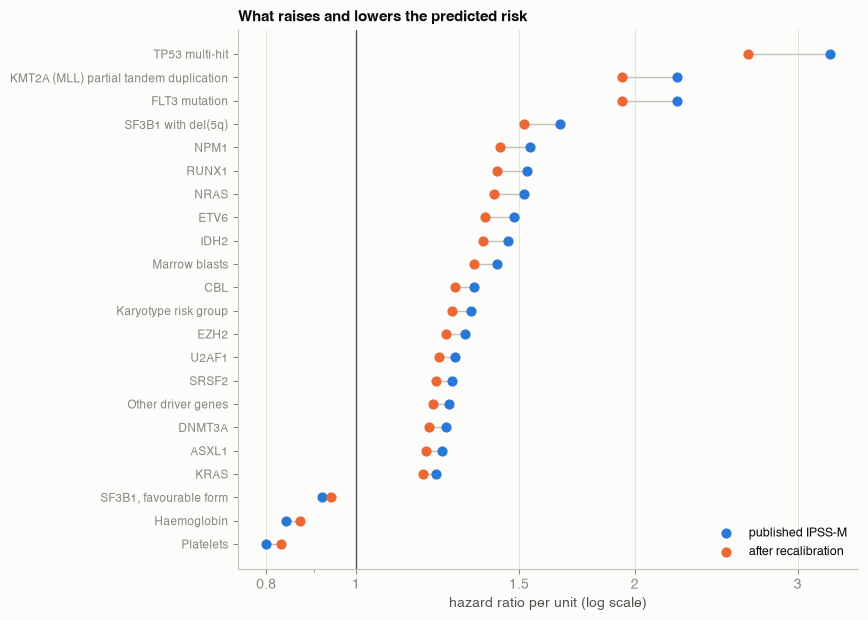

In [5]:
order = ft.sort_values("published_hazard_ratio")
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(order))
ax.scatter(order.published_hazard_ratio, y, color=plotting.SERIES[0], s=40, label="published IPSS-M", zorder=3)
ax.scatter(order.hazard_ratio_this_cohort, y, color=plotting.SERIES[1], s=40, label="after recalibration", zorder=3)
ax.hlines(y, order.hazard_ratio_this_cohort, order.published_hazard_ratio, color=plotting.AXIS, lw=1)
ax.axvline(1, color=plotting.INK2, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.8, 1, 1.5, 2, 3])
ax.set_xticklabels(["0.8", "1", "1.5", "2", "3"])
ax.set_yticks(y)
ax.set_yticklabels(order.feature, fontsize=8.5)
ax.set_xlabel("hazard ratio per unit (log scale)")
ax.set_title("What raises and lowers the predicted risk")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

Not in the model: neutrophils, white cells, monocytes and genes such as TET2 (adding them did not help, notebook 2). A weight is an association in the cohorts behind IPSS-M, not proof that a mutation causes the risk.

## 4. One prediction, by hand

Patient P132699: IPSS-R calls them Intermediate, IPSS-M Very High. Each feature contributes weight × (value − average) to the score.

In [6]:
pid = "P132699"
p = df.loc[pid]
x = p[list(scores.BETA)].astype(float).fillna(pd.Series(scores.MEAN))
work = pd.DataFrame({"value": x, "average": pd.Series(scores.MEAN), "weight": pd.Series(scores.BETA)})
work["contribution"] = (work.value - work.average) * work.weight / np.log(2)
work.index = [scores.FEATURES[k][0] for k in work.index]
by_hand = work.contribution.sum()
print(f"IPSS-M score by hand: {by_hand:.2f}   (scores.ipssm: {p.IPSSM_score:.2f}, category {p.IPSSM_cat})")
print(f"2-year risk by the formula: {risk_of(by_hand):.1%}")
work[work.contribution.abs() > 0.005].sort_values("contribution", key=abs, ascending=False).round(3)

IPSS-M score by hand: 1.70   (scores.ipssm: 1.70, category Very High)
2-year risk by the formula: 63.4%


,value,average,weight,contribution
Karyotype risk group,3.00,1.390,0.287,0.667
RUNX1,1.00,0.126,0.423,0.533
Marrow blasts,0.20,0.922,0.352,-0.367
EZH2,1.00,0.059,0.270,0.367
Haemoglobin,8.90,9.870,-0.171,0.239
ASXL1,1.00,0.252,0.213,0.230
Platelets,0.77,1.410,-0.222,0.205
Other driver genes,1.00,0.388,0.231,0.204
TP53 multi-hit,0.00,0.071,1.180,-0.121
SRSF2,0.00,0.158,0.239,-0.054


In [7]:
clin, muts = features.load("df_clinical_train.tsv", "mut_clinical_train.tsv")
m = tool.load_model()
pred, feats, contrib = tool.predict_full(clin, muts, m)
pred.loc[[pid], ["risk_2y", "risk_2y_low", "risk_2y_high", "band", "IPSSR_cat", "IPSSM_cat", "IPSSM_score"]].round(3)

,risk_2y,risk_2y_low,risk_2y_high,band,IPSSR_cat,IPSSM_cat,IPSSM_score
ID,,,,,,,
P132699,0.634,0.609,0.661,HIGHER,Intermediate,Very High,1.7


The tool gives the same 63 % as the hand calculation (it uses the unrounded score). The del(3q) karyotype plus RUNX1, EZH2 and ASXL1 mutations explain why IPSS-M sees a much higher risk than IPSS-R.

## 5. The tool on every patient

The **band** compares the whole uncertainty range with 30 %: Higher (range ≥ 30 %), Lower (range < 30 %), Borderline (range crosses 30 %: no advice), Out of intended use (blasts ≥ 20 %, WBC ≥ 13, or core labs missing).

In [8]:
ins = pred.index.isin(train.index)
bands = pred[ins].band.value_counts()
rows = []
for b in ["LOWER", "BORDERLINE", "HIGHER"]:
    x = train.loc[pred[ins & (pred.band == b)].index]
    rows.append(dict(band=b, patients=len(x), share=f"{len(x) / ins.sum():.1%}",
                     observed_2y_mortality=f"{1 - metrics.km_surv(x.OS_YEARS, x.OS_STATUS, H):.1%}"))
print("whole file:", pred.band.value_counts().to_dict())
pd.DataFrame(rows)

whole file: {'LOWER': 1371, 'HIGHER': 1163, 'OUT': 512, 'BORDERLINE': 277}


,band,patients,share,observed_2y_mortality
0,LOWER,1271,47.7%,14.3%
1,BORDERLINE,262,9.8%,28.7%
2,HIGHER,1129,42.4%,61.1%


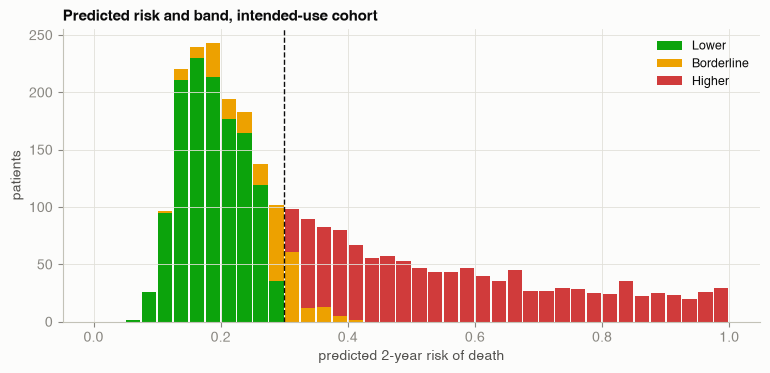

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 1, 41)
band_colors = {"LOWER": "#0ca30c", "BORDERLINE": "#eda100", "HIGHER": "#d03b3b"}
ax.hist([pred[ins & (pred.band == b)].risk_2y for b in band_colors], bins=bins, stacked=True,
        color=list(band_colors.values()), label=[b.title() for b in band_colors], rwidth=0.9)
ax.axvline(THRESHOLD, color=plotting.INK, ls="--", lw=1)
ax.set_xlabel("predicted 2-year risk of death")
ax.set_ylabel("patients")
ax.set_title("Predicted risk and band, intended-use cohort")
ax.legend()
plt.show()

### Why a patient is Borderline

Mostly because an input is missing: the range then spans the best and worst values that input could take.

borderline patients: 262; with a missing or unreadable karyotype: 63% (vs 9% overall)


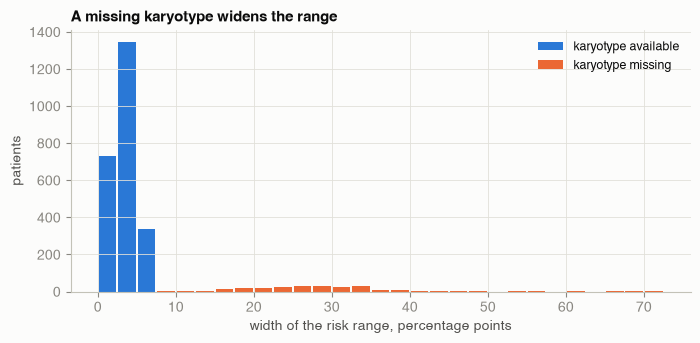

In [10]:
b = pred[ins & (pred.band == "BORDERLINE")]
print(f"borderline patients: {len(b)}; with a missing or unreadable karyotype: {feats.loc[b.index].CYTO_CAT.isna().mean():.0%} "
      f"(vs {feats.loc[pred[ins].index].CYTO_CAT.isna().mean():.0%} overall)")
width = (pred.risk_2y_high - pred.risk_2y_low)[ins]
has_k = feats.loc[width.index].CYTO_CAT.notna()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist([100 * width[has_k], 100 * width[~has_k]], bins=np.arange(0, 75, 2.5), stacked=True,
        color=[plotting.SERIES[0], plotting.SERIES[1]], label=["karyotype available", "karyotype missing"], rwidth=0.9)
ax.set_xlabel("width of the risk range, percentage points")
ax.set_ylabel("patients")
ax.set_title("A missing karyotype widens the range")
ax.legend()
plt.show()

### Centre-to-centre range

Absolute risk differs between hospitals (notebook 2). We estimated the between-centre spread on the log-hazard scale (τ, DerSimonian–Laird) and show, on each card, the range that 80 % of centres would observe.

In [11]:
oe = pd.read_csv("outputs/tables/centre_heterogeneity_oe.csv")
print(f"between-centre tau = {frozen['between_centre_tau']:.3f}  ->  80 % of centres within x{np.exp(-1.2816 * frozen['between_centre_tau']):.2f} to x{np.exp(1.2816 * frozen['between_centre_tau']):.2f} of the hazard")
oe.assign(observed_over_expected=np.exp(oe.log_oe)).sort_values("observed_over_expected")[["center", "observed", "expected", "observed_over_expected"]].round(2)

between-centre tau = 0.208  ->  80 % of centres within x0.77 to x1.31 of the hazard


,center,observed,expected,observed_over_expected
0,CCH,18,34.08,0.53
15,TUD,12,21.39,0.56
13,PV,28,47.39,0.59
16,UOB,29,40.53,0.72
11,MSK,12,16.66,0.72
8,ICO,16,20.95,0.76
10,KI,235,236.90,0.99
6,HIAE,17,17.13,0.99
4,FUCE,26,24.99,1.04
5,GESMD,65,57.92,1.12


## 6. What the meeting sees, and scoring new patients

Each patient gets a printable card (`outputs/cards/`). Below, the card for P132699.

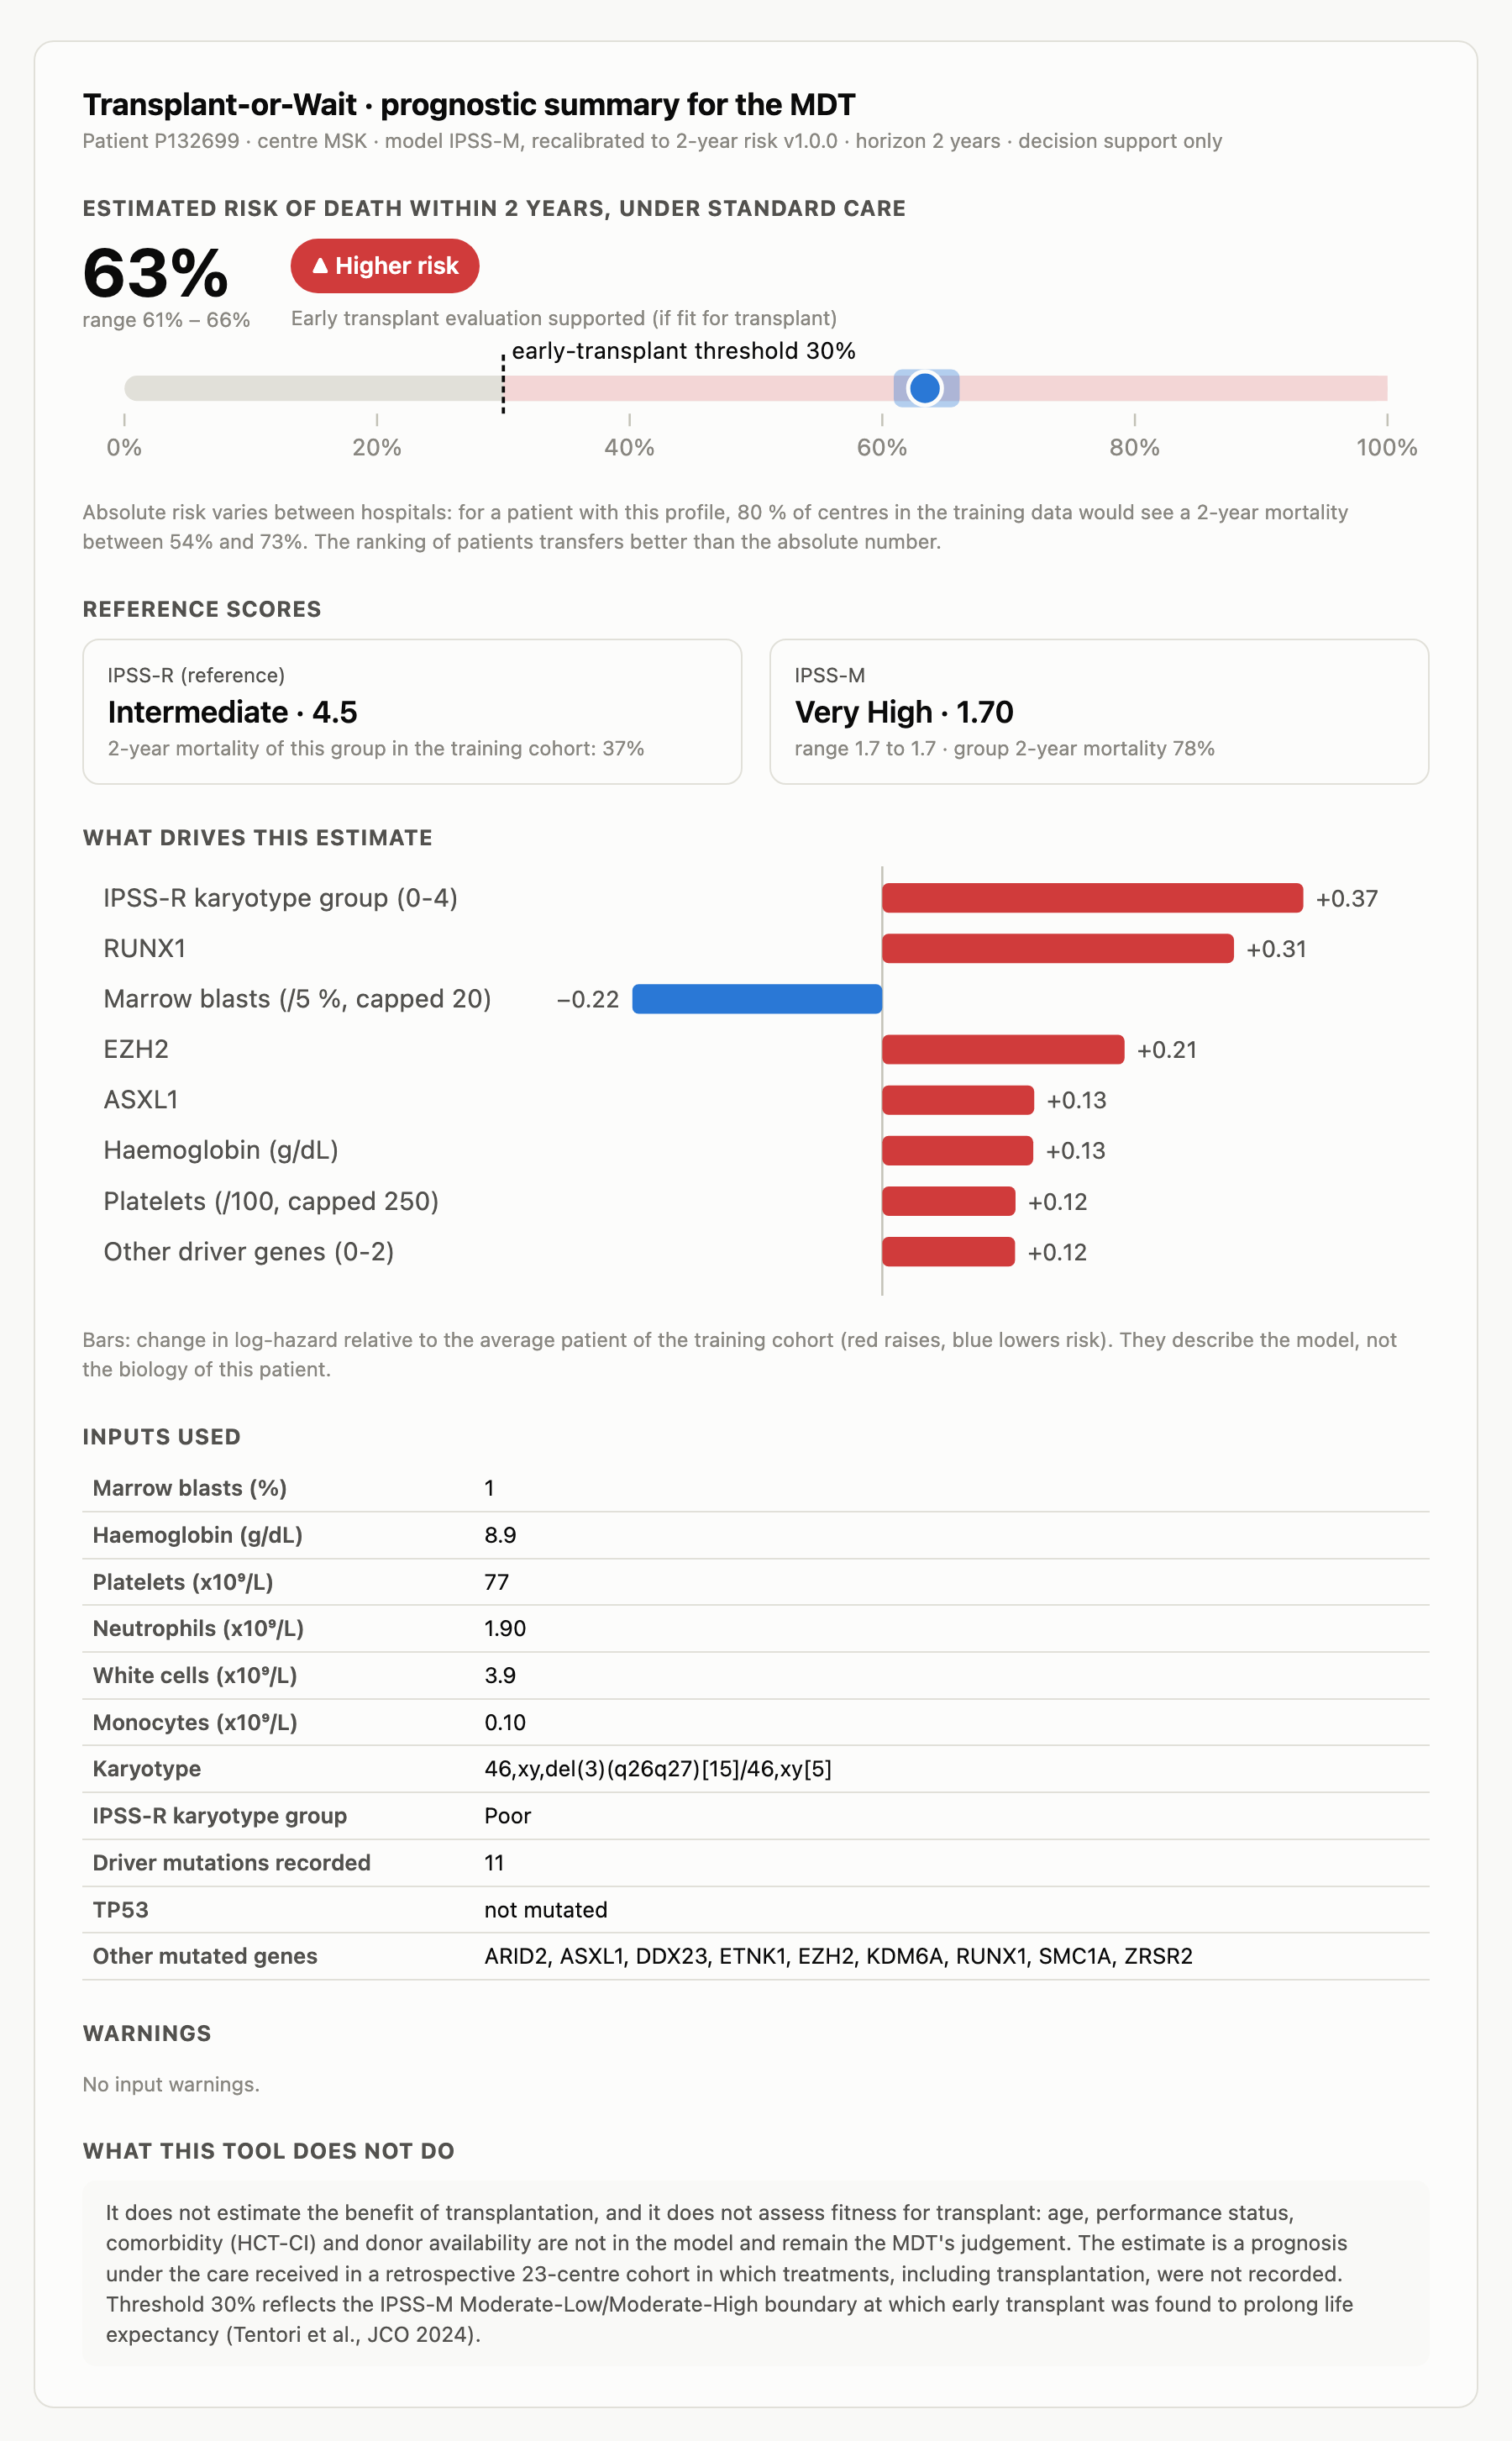

In [12]:
tool.write_cards(pred, feats, contrib, m, [pid], "outputs/cards")
display(Image(filename="outputs/figures/F10_card_P132699.png", width=700))

New patients (for example the instructor's held-out test set) need the same two files, without outcome columns:

```bash
.venv/bin/python scripts/predict.py --clinical test_clinical.tsv --mutations test_mutations.tsv --out predictions_test.csv
```

`risk_score` ranks patients for a C-index; `risk_2y`, its range and `band` are the decision outputs. The same call from Python, on 5 patients with their outcome removed:

In [13]:
sample = clin.sample(5, random_state=1).drop(columns=["OS_YEARS", "OS_STATUS"])
new = tool.predict(sample, muts[muts.ID.isin(sample.ID)], m)
new[["CENTER", "risk_score", "risk_2y", "risk_2y_low", "risk_2y_high", "band", "IPSSR_cat", "IPSSM_cat", "warnings"]].round(3)

,CENTER,risk_score,risk_2y,risk_2y_low,risk_2y_high,band,IPSSR_cat,IPSSM_cat,warnings
ID,,,,,,,,,
P131873,KI,-0.960,0.139,0.129,0.151,LOWER,Low,Very Low,No mutation recorded: confirm the panel was run (treated as wild type)
P100263,PV,-0.326,0.246,0.233,0.259,LOWER,Low,Low,
P131485,TUD,0.311,0.413,0.398,0.432,OUT,High,High,"Marrow blasts >= 20 %: AML range, outside intended use"
P121102,KI,2.556,0.993,0.988,0.997,HIGHER,Very high,Very High,
P116634,KI,0.905,0.619,0.595,0.646,HIGHER,High,Very High,Neutrophil count missing


## 7. Pre-registered expectations for the held-out test set

Written before the test set is scored (report, "Pre-registration"):

| Quantity (intended-use patients) | Expected |
| --- | --- |
| Harrell C-index | 0.745 (accept 0.72–0.77) |
| Time-dependent AUC at 2 years | 0.80 (0.77–0.83) |
| Observed / expected 2-year deaths | 0.85–1.15 |
| Bands | about 48 % Lower, 42 % Higher, 10 % Borderline |
| **Error we cannot accept** | Lower-band 2-year mortality above 18 %, or any TP53 multi-hit patient in the Lower band |

The training-set values of the last line:

In [14]:
low = train.loc[pred[ins & (pred.band == "LOWER")].index]
print(f"Lower band: 2-year mortality {1 - metrics.km_surv(low.OS_YEARS, low.OS_STATUS, H):.1%}; "
      f"TP53 multi-hit patients in it: {int((low.TP53multi == 1).sum())} of {int((train.TP53multi == 1).sum())}")

Lower band: 2-year mortality 14.3%; TP53 multi-hit patients in it: 0 of 179
